# TEPCO's forecast as a yardstick

The plan sets the model beside one more forecast than its baselines: TEPCO's own next-day forecast for its area, and it weights the model's error by the JEPX price. Neither source has a DWD model yet. This notebook asks one question before they are built: **what is a fair comparison with TEPCO's forecast?** It also reads the price file far enough to say when a price is known and what weighting an error by it does.

"Fair" means both forecasts are scored on the same thing, over the same slots, in the same way, with the one difference that can't be removed said openly: TEPCO's forecast is made later than ours.

Written down before it was run:

| We assumed | What would make us think again |
| --- | --- |
| TEPCO's forecast beats ours: it is published the evening before, hours after our 09:00 decision | If it doesn't, we misread its number or set the comparison up wrong |
| Wind is small beside solar in the Tokyo area, so a comparison of wind plus solar is mostly about solar | If wind or its error is large, the combined score says little about a solar forecast |
| A plain stand-in for wind on our side is enough: the same slot two days back | The same |
| TEPCO forecasts what is delivered, so curtailed output is not part of it | A curtailed day where its figure sits near delivered plus curtailed |
| Its area is the actuals' area | A steady gap between its forecast and the actuals on clear days |
| Its unit is kWh per half hour, so MW is the figure over 500 | Peaks that don't fit the fleet |
| One version per target day is enough | A day where a later capture differs |

The capture began on 15 November 2026 and TEPCO keeps no archive of this file ([notebook 00](00_source_probe.ipynb)), so there are five target days. Nothing here is a result about which forecast is better in general.

## 0. What the file holds

**Step.** `AREA_ONCE_YOSOKU.csv` is captured at 19:00 and 22:00 each evening ([notebook 02](02_raw_to_ods.ipynb), section 7). Per capture: the day it forecasts, the update time written in the file, its slots, its peak and its total for wind plus solar, and a hash of its 48 values to tell whether two captures differ.

In [1]:
import os
import warnings
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from jtf.ml.models import KEPT_INPUTS, columns_of, scaled_mean, train_boosted
from jtf.ml.replay import train_by_month
from jtf.ml.warehouse import BacktestWarehouse

warnings.filterwarnings("ignore", message="BigQuery Storage module not found")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 70)
pd.set_option("display.float_format", "{:,.2f}".format)


def setting(name: str) -> str:
    if value := os.environ.get(name):
        return value
    lines = Path("../.env").read_text().splitlines()
    env = dict(line.split("=", 1) for line in lines if "=" in line and not line.startswith("#"))
    return env[name]


PROJECT, PREFIX = setting("JTF_BIGQUERY_PROJECT"), setting("JTF_DBT_DATASET_PREFIX")
warehouse = BacktestWarehouse(PROJECT, setting("JTF_BIGQUERY_LOCATION"), PREFIX)
ODS = f"{PROJECT}.ods"
DWD, DWS, DIM, ADS = (f"{PROJECT}.{PREFIX}_{layer}" for layer in ("dwd", "dws", "dim", "ads"))


def sql(query: str) -> pd.DataFrame:
    return warehouse.client.query(query).to_dataframe(create_bqstorage_client=False)


JST = "Asia/Tokyo"
captures = sql(f"""
    SELECT target_date, source_file,
      FORMAT_TIMESTAMP('%m-%d %H:%M', ANY_VALUE(fetched_at), '{JST}') AS fetched_jst,
      FORMAT_TIMESTAMP('%m-%d %H:%M', ANY_VALUE(source_time), '{JST}') AS file_updated_jst,
      COUNT(*) AS slots, MIN(slot_code) AS first_slot, MAX(slot_code) AS last_slot,
      ROUND(MAX(wind_solar_kwh) / 500) AS peak_mw, ROUND(SUM(wind_solar_kwh) / 1e6, 1) AS day_gwh,
      CAST(SUM(FARM_FINGERPRINT(FORMAT('%d %d', slot_code, wind_solar_kwh)) / 1e6) AS INT64)
        AS values_hash
    FROM `{ODS}.tepco_area_forecast_next_day`
    GROUP BY target_date, source_file
    ORDER BY target_date, fetched_jst
""")
captures["source_file"] = captures["source_file"].str.split("/").str[-1]
captures

,target_date,source_file,fetched_jst,file_updated_jst,slots,first_slot,last_slot,peak_mw,day_gwh,values_hash
0,20261116,20261115T100018Z_AREA_ONCE_YOSOKU.csv,11-15 19:00,11-15 18:50,48,1,48,"12,295.00",74.30,39087081730480
1,20261116,20261115T130023Z_AREA_ONCE_YOSOKU.csv,11-15 22:00,11-15 21:50,48,1,48,"12,295.00",74.30,39087081730480
2,20261117,20261116T100047Z_AREA_ONCE_YOSOKU.csv,11-16 19:00,11-16 18:50,48,1,48,"2,784.00",17.20,34276422781519
3,20261117,20261116T130053Z_AREA_ONCE_YOSOKU.csv,11-16 22:00,11-16 21:50,48,1,48,"2,784.00",17.20,34276422781519
4,20261117,20261116T130032Z_AREA_ONCE_YOSOKU.csv,11-16 22:00,11-16 21:50,48,1,48,"2,784.00",17.20,34276422781519
5,20261118,20261117T100033Z_AREA_ONCE_YOSOKU.csv,11-17 19:00,11-17 18:50,48,1,48,"13,085.00",77.20,-35581808838534
6,20261118,20261117T130029Z_AREA_ONCE_YOSOKU.csv,11-17 22:00,11-17 21:50,48,1,48,"13,085.00",77.20,-35581808838534
7,20261119,20261118T100032Z_AREA_ONCE_YOSOKU.csv,11-18 19:00,11-18 18:50,48,1,48,"13,531.00",83.80,24832059876950
8,20261119,20261118T130027Z_AREA_ONCE_YOSOKU.csv,11-18 22:00,11-18 21:50,48,1,48,"13,531.00",83.80,24832059876950
9,20261120,20261119T100043Z_AREA_ONCE_YOSOKU.csv,11-19 19:00,11-19 18:50,48,1,48,"13,629.00",84.00,416375573060


**What it shows.** **Observed:**

- **Five target days, 16 to 20 November,** each captured twice the evening before (three times for the 17th, when the 22:00 capture ran twice)
- **Every capture holds 48 slots,** numbered 1 to 48
- **The captures of a day are identical:** the same hash at 19:00 and at 22:00
- **The file says it was updated ten minutes before each capture,** at 18:50 and at 21:50, with the same values. So the update time is when the file was last written, not when the forecast was made
- **The peaks fit a fleet of about 21,000 MW in November:** 12,300 to 13,600 MW on four days, 2,800 MW on the 17th

**Learned → design:**

- **A value is known from the first capture that holds it:** 19:00 on the day before. When TEPCO first published it that day can't be read from the file; the capture time errs late, as the plan's rule asks
- **A later capture with the same values is not a new version**

## 1. Against what happened

**Step.** Each forecast slot in MW (kWh over 500), beside the latest actuals for solar, curtailed solar and wind, and the same slot's wind two days earlier as it was known at 09:00 on the day before (read from `dwd_tepco_actuals` at that time).

In [2]:
# Every slot TEPCO forecast: its figure in MW, what happened (the latest actuals), the same slot's
# wind two days earlier as it was known at 09:00 the day before, and whether the slot is night
slots = sql(f"""
    WITH forecast AS (
      SELECT TIMESTAMP(
          DATETIME(PARSE_DATE('%Y%m%d', date), PARSE_TIME('%H%M', slot_from)), '{JST}'
        ) AS slot_start,
        ANY_VALUE(wind_solar_kwh) / 500 AS tepco_mw, COUNT(DISTINCT wind_solar_kwh) AS values_seen
      FROM `{ODS}.tepco_area_forecast_next_day`
      GROUP BY slot_start
    ),
    latest AS (
      SELECT slot_start, measure, value_mw FROM `{DWD}.dwd_tepco_actuals` WHERE known_until IS NULL
    ),
    happened AS (
      SELECT slot_start, MAX(IF(measure = 'solar', value_mw, NULL)) AS solar_mw,
        MAX(IF(measure = 'solar_curtailed', value_mw, NULL)) AS curtailed_mw,
        MAX(IF(measure = 'wind', value_mw, NULL)) AS wind_mw
      FROM latest GROUP BY slot_start
    ),
    two_days_back AS (
      SELECT f.slot_start, a.value_mw AS wind_d2_mw
      FROM forecast AS f
      INNER JOIN `{DWD}.dwd_tepco_actuals` AS a
        ON a.slot_start = TIMESTAMP_SUB(f.slot_start, INTERVAL 48 HOUR) AND a.measure = 'wind'
      CROSS JOIN UNNEST([TIMESTAMP(DATETIME(
          DATE_SUB(DATE(f.slot_start, '{JST}'), INTERVAL 1 DAY), TIME '09:00:00'), '{JST}')]) AS t
      WHERE a.known_at <= t AND (a.known_until IS NULL OR t < a.known_until)
    )
    SELECT f.slot_start, DATE(f.slot_start, '{JST}') AS day, f.tepco_mw, f.values_seen,
      h.solar_mw, h.curtailed_mw, h.wind_mw, w.wind_d2_mw, NOT d.is_night AS is_daylight
    FROM forecast AS f
    LEFT JOIN happened AS h USING (slot_start)
    LEFT JOIN two_days_back AS w USING (slot_start)
    LEFT JOIN `{DIM}.dim_daylight` AS d USING (slot_start)
    ORDER BY f.slot_start
""")
slots["actual_mw"] = slots["solar_mw"] + slots["wind_mw"]
per_day = slots.groupby("day").agg(
    slots=("tepco_mw", "size"),
    with_actuals=("actual_mw", "count"),
    values_seen=("values_seen", "max"),
    tepco_peak=("tepco_mw", "max"),
    actual_peak=("actual_mw", "max"),
    solar_peak=("solar_mw", "max"),
    wind_mean=("wind_mw", "mean"),
    wind_max=("wind_mw", "max"),
    curtailed=("curtailed_mw", "sum"),
    wind_d2_known=("wind_d2_mw", "count"),
)
per_day

,slots,with_actuals,values_seen,tepco_peak,actual_peak,solar_peak,wind_mean,wind_max,curtailed,wind_d2_known
day,,,,,,,,,,
2026-11-16,48,48,1,"12,294.65","13,348.00","13,040.00",242.60,323.00,0.00,48
2026-11-17,48,48,1,"2,784.08","1,612.00","1,487.00",126.19,164.00,0.00,48
2026-11-18,48,48,1,"13,084.72","12,577.00","12,307.00",195.44,383.00,0.00,48
2026-11-19,48,48,1,"13,531.29","13,603.00","13,222.00",351.40,387.00,0.00,48
2026-11-20,48,17,1,"13,628.90","5,910.00","5,605.00",290.35,305.00,0.00,48


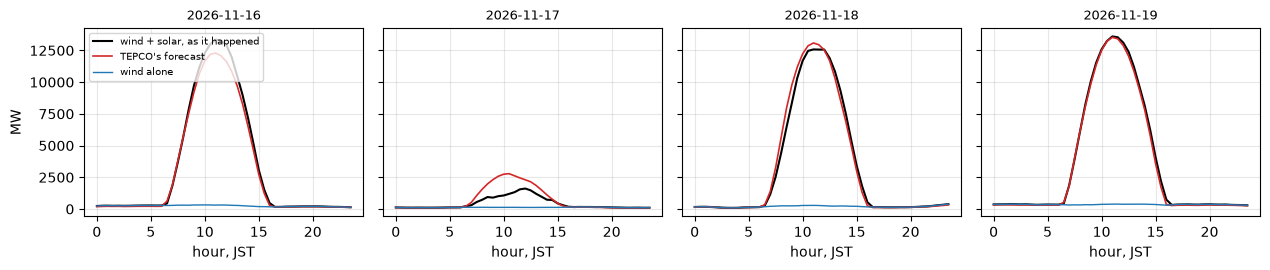

days with every slot's actuals: ['2026-11-16', '2026-11-17', '2026-11-18', '2026-11-19']


In [3]:
whole = per_day.index[per_day["with_actuals"] == 48]
fig, axes = plt.subplots(1, len(whole), figsize=(3.2 * len(whole), 2.8), sharey=True)
axes = np.atleast_1d(axes)
for ax, day in zip(axes, whole, strict=True):
    one = slots[slots["day"] == day]
    local = one["slot_start"].dt.tz_convert(JST)
    hours = local.dt.hour + local.dt.minute / 60
    ax.plot(hours, one["actual_mw"], color="black", lw=1.5, label="wind + solar, as it happened")
    ax.plot(hours, one["tepco_mw"], color="tab:red", lw=1.2, label="TEPCO's forecast")
    ax.plot(hours, one["wind_mw"], color="tab:blue", lw=1, label="wind alone")
    ax.set_title(str(day), fontsize=9)
    ax.set_xlabel("hour, JST")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("MW")
axes[0].legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()
print("days with every slot's actuals:", [str(d) for d in whole])

**What it shows.** **Observed:**

- **Four days have all their actuals:** 16 to 19 November. The 20th is today and has 17 slots so far
- **The forecast follows the day:** on the three sunny days its peak is within 8% of what happened, above on one and below on two. On the 17th, a day of rain, it said 2,800 MW and 1,600 came
- **No day was curtailed,** so nothing here says whether TEPCO's figure includes curtailed output
- **Wind two days back was known at 09:00 for every slot**

**Learned → design:** the unit is right, and nothing suggests another area: no steady gap on the sunny days. Whether curtailed output belongs in the comparison stays open until a curtailed day is captured; until then the forecast is scored against delivered wind plus solar.

## 2. Wind beside solar

**Step.** Daylight slots of the last year, from the latest actuals: how large wind is, and how far the same slot two days earlier is from it.

In [4]:
# Wind beside solar over the last year of daylight slots, from the latest actuals
year = sql(f"""
    WITH latest AS (
      SELECT slot_start, MAX(IF(measure = 'solar', value_mw, NULL)) AS solar_mw,
        MAX(IF(measure = 'wind', value_mw, NULL)) AS wind_mw
      FROM `{DWD}.dwd_tepco_actuals`
      WHERE known_until IS NULL AND slot_start >= TIMESTAMP('2025-11-01', '{JST}')
      GROUP BY slot_start
    )
    SELECT l.slot_start, l.solar_mw, l.wind_mw, NOT d.is_night AS is_daylight
    FROM latest AS l INNER JOIN `{DIM}.dim_daylight` AS d USING (slot_start)
    ORDER BY l.slot_start
""")
lit = year[year["is_daylight"].astype(bool)].copy()
lit["wind_d2_mw"] = year["wind_mw"].shift(96).loc[lit.index]  # the same slot two days earlier
miss = (lit["wind_d2_mw"] - lit["wind_mw"]).abs()
wind, solar = lit["wind_mw"], lit["solar_mw"]
first_slot, last_slot = lit["slot_start"].min(), lit["slot_start"].max()
print(f"daylight slots: {len(lit):,}, {first_slot:%Y-%m-%d} to {last_slot:%Y-%m-%d}")
print(
    f"wind: mean {wind.mean():.0f} MW, 99th percentile {wind.quantile(0.99):.0f}, "
    f"highest {wind.max():.0f}; solar: mean {solar.mean():.0f}, highest {solar.max():.0f}"
)
print(f"wind's share of wind + solar in daylight: {wind.sum() / (wind + solar).sum():.1%}")
print(
    f"wind two days back misses wind by {miss.mean():.0f} MW on average, "
    f"{miss.quantile(0.95):.0f} at the 95th percentile"
)

daylight slots: 9,681, 2025-10-31 to 2026-11-19
wind: mean 145 MW, 99th percentile 401, highest 486; solar: mean 5336, highest 17840
wind's share of wind + solar in daylight: 2.6%
wind two days back misses wind by 95 MW on average, 256 at the 95th percentile


**What it shows.** **Observed:**

- **Wind is 2.6% of wind plus solar in daylight:** 145 MW on average against solar's 5,336, and never above 486 MW
- **Wind two days back misses by 95 MW on average,** 0.45% of capacity, and by 256 MW at the 95th percentile

**Learned → design:** both assumptions about wind hold. The comparison is about solar, and the simplest stand-in for wind costs less than half a point of capacity.

## 3. The comparison

**Step.** Our forecasts for the same days are made as a run makes them: the model is trained on the labelled days up to 30 October, two days before November began, and predicts from the features as known at 09:00 on the day before, with `jtf.ml`'s own code. The scaled seven-day mean, the strongest baseline, is made from the same features. Wind two days back is added to both. Then each forecast is scored against delivered wind plus solar on the daylight slots of the four whole days, as a share of capacity.

A fourth row gives our model the wind that happened, to see what the stand-in costs.

In [5]:
# Our forecasts for the same days, made as a run makes them: the model trained on the labelled
# days to 30 October, two days before November began, and features as known at 09:00 the day before
columns = columns_of(KEPT_INPUTS)  # the scaled seven-day mean reads a subset of the same columns
first, last = min(whole), max(whole)
features = warehouse.features(first, last, columns)
known = warehouse.training(date(2026, 10, 30), columns_of(KEPT_INPUTS))
said, trainings = train_by_month(train_boosted, known, features)
ours = features[["slot_start", "capacity_mw"]].assign(
    model_mw=said["predicted_mw"], rule_mw=scaled_mean(features)
)
both = slots[slots["day"].isin(whole)].merge(ours, on="slot_start", validate="1:1")
print(
    f"{len(known):,} labelled slots trained on, to {known['target_day'].max()}; "
    f"{len(both)} slots on {both['day'].nunique()} days to compare; "
    f"capacity {both['capacity_mw'].mean():,.0f} MW"
)
print(
    "slots where wind two days back was not known at 09:00 the day before:",
    int(both["wind_d2_mw"].isna().sum()),
)

47,376 labelled slots trained on, to 2026-10-30; 192 slots on 4 days to compare; capacity 21,038 MW
slots where wind two days back was not known at 09:00 the day before: 0


In [6]:
lit_days = both[both["is_daylight"].astype(bool)]
actual, capacity = lit_days["actual_mw"], lit_days["capacity_mw"]
forecasts = {
    "TEPCO, wind + solar": lit_days["tepco_mw"],
    "model + wind two days back": lit_days["model_mw"] + lit_days["wind_d2_mw"],
    "scaled seven-day mean + wind two days back": lit_days["rule_mw"] + lit_days["wind_d2_mw"],
    "model + wind as it happened": lit_days["model_mw"] + lit_days["wind_mw"],
}
errors = pd.DataFrame({name: (said - actual) / capacity for name, said in forecasts.items()})
scores = pd.DataFrame(
    {
        "mae, % of capacity": errors.abs().mean() * 100,
        "bias, % of capacity": errors.mean() * 100,
        "mae, MW": errors.abs().mul(capacity, axis=0).mean(),
    }
)
by_day = (errors.abs().groupby(lit_days["day"]).mean() * 100).T
print(f"{len(lit_days)} daylight slots on {lit_days['day'].nunique()} days")
display(scores)
by_day

88 daylight slots on 4 days


,"mae, % of capacity","bias, % of capacity","mae, MW"
"TEPCO, wind + solar",2.25,0.17,474.37
model + wind two days back,4.10,0.16,863.36
scaled seven-day mean + wind two days back,6.12,-1.99,"1,288.59"
model + wind as it happened,3.73,0.75,783.82


day,2026-11-16,2026-11-17,2026-11-18,2026-11-19
"TEPCO, wind + solar",2.46,3.05,2.53,0.97
model + wind two days back,1.89,6.90,5.07,2.56
scaled seven-day mean + wind two days back,5.98,7.75,5.10,5.66
model + wind as it happened,1.07,7.19,4.96,1.69


**What it shows.** **Observed**, on 88 daylight slots of four days:

| Forecast | Made | Miss, % of capacity |
| --- | --- | --- |
| TEPCO's | By 19:00 the day before | 2.25 |
| Our model, with wind two days back | 09:00 the day before | 4.10 |
| The scaled seven-day mean, with wind two days back | 09:00 the day before | 6.12 |

- **TEPCO's is ahead on three days of four.** On the 16th ours was closer: 1.9% against 2.5%
- **The rainy day is where ours is furthest behind:** 6.9% against 3.1% on the 17th
- **The wind stand-in costs 0.4 points:** with the wind that happened, our model would score 3.73%
- **None is biased over these days:** 0.2 points for TEPCO's and for ours

**Learned → design:**

- **The first assumption holds, on four days:** TEPCO's forecast, made about ten hours later, misses by about half of what ours does. Of the 1.85 points between them, up to 0.4 is wind
- **The comparison is: TEPCO's wind plus solar forecast against our solar forecast plus wind two days back,** both scored against delivered wind plus solar on daylight slots, over capacity, with the number of days said beside every figure
- **The model keeps its place between the rule and TEPCO:** the order is the one the baselines' ladder predicts

## 4. The other file of the page

**Step.** The same page publishes `AREA_ONCE_BGKEI.csv`, the balancing groups' plans for tomorrow ([notebook 02](02_raw_to_ods.ipynb), section 7), with the same columns. Its wind plus solar is set beside the forecast's.

In [7]:
# The second file of the same page, AREA_ONCE_BGKEI: the same columns, another figure
def per_slot(table: str) -> str:
    return f"""(SELECT target_date, slot_code, ANY_VALUE(wind_solar_kwh) AS wind_solar_kwh
        FROM `{ODS}.{table}` GROUP BY target_date, slot_code)"""


plan = sql(f"""
    SELECT f.target_date, ROUND(MAX(f.wind_solar_kwh) / 500) AS forecast_peak_mw,
      ROUND(MAX(p.wind_solar_kwh) / 500) AS plan_peak_mw,
      ROUND(SUM(f.wind_solar_kwh) / 1e6, 1) AS forecast_gwh,
      ROUND(SUM(p.wind_solar_kwh) / 1e6, 1) AS plan_gwh
    FROM {per_slot("tepco_area_forecast_next_day")} AS f
    INNER JOIN {per_slot("tepco_area_bg_plan_next_day")} AS p USING (target_date, slot_code)
    GROUP BY f.target_date ORDER BY f.target_date
""")
plan["plan over forecast"] = plan["plan_gwh"] / plan["forecast_gwh"] - 1
plan

,target_date,forecast_peak_mw,plan_peak_mw,forecast_gwh,plan_gwh,plan over forecast
0,20261116,"12,295.00","11,633.00",74.30,70.70,-0.05
1,20261117,"2,784.00","3,267.00",17.20,19.90,0.16
2,20261118,"13,085.00","11,571.00",77.20,67.30,-0.13
3,20261119,"13,531.00","12,906.00",83.80,81.70,-0.03
4,20261120,"13,629.00","13,059.00",84.00,81.90,-0.02


**What it shows.** **Observed:** it is another figure. On the four sunny days the plans hold 2 to 13% less wind and solar than TEPCO's forecast; on the rainy day, 16% more.

**Learned → design:** the plans are what the market's participants intended to deliver, not a forecast of what the weather allows. They are left out of the comparison. They stay in ODS, where a later question can find them.

## 5. The price

**Step.** `ods.jepx_spot` holds every delivery day since April 2016: ten yearly files from the initial load, and the current fiscal year's file, captured daily at 11:00. Per delivery day: its slots, which capture held it first, and whether any slot ever showed two prices.

In [8]:
# The Tokyo price per slot: which file holds a day first, and whether a price ever changes
seen = sql(f"""
    WITH sightings AS (
      SELECT PARSE_DATE('%Y/%m/%d', delivery_date) AS day, slot_code, price_tokyo_yen_kwh AS price,
        fetched_at, load_type
      FROM `{ODS}.jepx_spot`
    ),
    per_slot AS (
      SELECT day, slot_code, MIN(fetched_at) AS first_seen, COUNT(*) AS sightings,
        COUNT(DISTINCT price) AS prices, MIN_BY(load_type, fetched_at) AS first_load
      FROM sightings GROUP BY day, slot_code
    )
    SELECT day, COUNT(*) AS slots, MAX(prices) AS most_prices_for_a_slot,
      ANY_VALUE(first_load) AS first_load,
      FORMAT_TIMESTAMP('%m-%d %H:%M', MIN(first_seen), '{JST}') AS first_seen_jst,
      MAX(sightings) AS captures
    FROM per_slot GROUP BY day ORDER BY day
""")
print(
    f"{len(seen):,} delivery days, {seen['day'].min()} to {seen['day'].max()}; "
    f"days without 48 slots: {int((seen['slots'] != 48).sum())}; "
    f"slots that ever showed two prices: {int((seen['most_prices_for_a_slot'] > 1).sum())}"
)
seen.tail(8)

3,887 delivery days, 2016-04-01 to 2026-11-21; days without 48 slots: 0; slots that ever showed two prices: 0


,day,slots,most_prices_for_a_slot,first_load,first_seen_jst,captures
3879,2026-11-14,48,1,daily,11-15 11:08,8
3880,2026-11-15,48,1,daily,11-15 11:08,8
3881,2026-11-16,48,1,daily,11-15 11:08,8
3882,2026-11-17,48,1,daily,11-16 11:00,5
3883,2026-11-18,48,1,daily,11-17 11:00,4
3884,2026-11-19,48,1,daily,11-18 11:00,3
3885,2026-11-20,48,1,daily,11-19 11:00,2
3886,2026-11-21,48,1,daily,11-20 11:00,1


**What it shows.** **Observed:**

- **3,887 delivery days, 1 April 2016 to 21 November 2026, each with 48 slots**
- **No slot has ever shown two prices** across up to eight captures: a published price is not corrected
- **Since capture began, a day's prices are first seen at 11:00 the day before**

**Source.** The [JEPX trading guide](https://www.jepx.jp/electricpower/outline/pdf/Guide_2.00.pdf) (January 2019 revision), p.8, as read in [notebook 00](00_source_probe.ipynb): 「毎日，10時に入札を締め切り，翌日分の取引計算を行います。」 Every day, bidding closes at 10:00 and the next day's trades are calculated.

**Learned → design:**

- **The price for day D is not known at 09:00 on D−1,** an hour before bidding closes. It is never an input to a forecast for D; the newest price a forecast can read is D−1's, as the plan says
- **`known_at` for a price:** the first capture that holds it, 11:00 on the day before; for the history before capture began, the plan's rule, 10:30 on the day before
- **A version per slot is still kept,** so a correction would show if one ever came

**Step.** The error weighted by the price: each slot's miss times the Tokyo price of that slot, summed, over the sum of the prices. It is tried on the two recorded runs to October 2026, the model's and the scaled seven-day mean's, for the months choices were made on and for the held-back months.

In [9]:
# Each recorded forecast's miss beside the price of its slot, for the two runs to October 2026
priced = sql(f"""
    WITH price AS (
      SELECT TIMESTAMP_ADD(TIMESTAMP(PARSE_DATE('%Y/%m/%d', delivery_date), '{JST}'),
          INTERVAL (slot_code - 1) * 30 MINUTE) AS slot_start,
        ANY_VALUE(price_tokyo_yen_kwh) AS price
      FROM `{ODS}.jepx_spot` GROUP BY slot_start
    )
    SELECT o.model, o.target_day, o.slot_start, o.error_share, o.error_mw, p.price,
      o.target_day >= '2026-07-01' AS held_back
    FROM `{ADS}.ads_ml_outcome_solar` AS o
    LEFT JOIN price AS p USING (slot_start)
    WHERE REGEXP_CONTAINS(o.run_id, r'^(623db0c2|73df2064)')
      AND o.is_daylight AND o.error_mw IS NOT NULL
    ORDER BY o.model, o.slot_start
""")
print("scored slots without a price:", int(priced["price"].isna().sum()), "of", len(priced))
once = priced[priced["model"] == "lgbm_quantiles"]  # each scored slot once
hour = once["slot_start"].dt.tz_convert(JST).dt.hour
print(
    "mean price by hour of day, daylight slots (yen/kWh):",
    once.groupby(hour)["price"].mean().round(1).to_dict(),
)
print(f"daylight slots priced at 0.01 yen: {(once['price'] <= 0.01).mean():.1%}")


def weighted(rows: pd.DataFrame) -> pd.Series:
    miss = rows["error_share"].abs()
    worst = miss >= miss.quantile(0.9)
    return pd.Series(
        {
            "slots": len(rows),
            "mae, %": miss.mean() * 100,
            "price-weighted, %": (miss * rows["price"]).sum() / rows["price"].sum() * 100,
            "mean price, yen/kWh": rows["price"].mean(),
            "price at the largest misses (top tenth)": rows.loc[worst, "price"].mean(),
        }
    )


table = priced.groupby(["held_back", "model"]).apply(weighted, include_groups=False)
for name in ("mae, %", "price-weighted, %"):
    table[f"skill by {name[:-3]}"] = 1 - table[name] / table.groupby("held_back")[name].transform(
        "max"
    )
table

scored slots without a price: 0 of 31870
mean price by hour of day, daylight slots (yen/kWh): {4: 14.7, 5: 15.1, 6: 14.4, 7: 14.0, 8: 14.1, 9: 14.1, 10: 13.2, 11: 13.1, 12: 12.3, 13: 14.2, 14: 15.8, 15: 17.1, 16: 19.3, 17: 20.7, 18: 22.5, 19: 20.4}
daylight slots priced at 0.01 yen: 1.6%


slots  mae, %  price-weighted, %  mean price, yen/kWh  price at the largest misses (top tenth)  skill by mae  skill by price-weighted
held_back model                                                                                                                                                   
False     lgbm_quantiles 12,652.00    5.21               5.00                13.42                                    12.92          0.14                     0.12
          mean_7d_scaled 12,652.00    6.06               5.67                13.42                                    12.64          0.00                     0.00
True      lgbm_quantiles  3,283.00    5.53               5.22                22.64                                    20.36          0.10                     0.07
          mean_7d_scaled  3,283.00    6.16               5.65                22.64                                    19.25          0.00                     0.00

**What it shows.** **Observed:**

- **Every scored slot has a price**
- **Prices are lowest when solar output is highest:** 12 to 13 yen per kWh around noon, 20 to 23 in the early evening. 1.6% of daylight slots cleared at 0.01 yen
- **Weighted by price, every miss is a little smaller:** the model's 5.21% becomes 5.00%, the rule's 6.06% becomes 5.67%. The largest misses fall in cheaper slots than the average
- **The model's lead shrinks:** a skill of 0.12 where the plain error gives 0.14, and 0.07 where it gives 0.10 on the held-back months

**Learned → design:**

- **The price-weighted error is reported beside the plain one, never in its place.** It answers another question: not how far off the forecast was, but how far off where a megawatt-hour was worth most
- **The rule gains more from the weighting than the model does:** its misses are largest around noon on sunny days, when prices are lowest. So the model's advantage is somewhat less in money than in megawatts

## What this exploration made known

| We assumed | We found | So |
| --- | --- | --- |
| TEPCO's forecast beats ours | On four days, 88 daylight slots: 2.25% of capacity against our 4.10% and the rule's 6.12%. Ahead on three days of four (section 3) | It does, so far. The gap is what about ten hours and an operator's information are worth; it is reported with its number of days |
| Wind is small beside solar | 2.6% of wind plus solar in daylight over the last year, never above 486 MW (section 2) | **The comparison is about solar** |
| The same slot two days back is enough for wind | It misses by 95 MW, 0.45% of capacity; in the comparison it costs our side 0.4 points (sections 2, 3) | **Our side is the solar forecast plus wind two days back,** as known at 09:00 |
| TEPCO forecasts what is delivered | No curtailed day in the capture so far (section 1) | Scored against delivered wind plus solar; looked at again on the first curtailed day |
| Its area is the actuals' area | No steady gap on sunny days: its peak is above on one and below on two (section 1) | Nothing to correct |
| Its unit is kWh per half hour | Peaks of 12,300 to 13,600 MW beside actual peaks of 12,600 to 13,600 (sections 0, 1) | **MW is the figure over 500** |
| One version per target day is enough | The captures of a day are identical; the file's update time moves with every capture and says nothing (section 0) | **Known from the first capture, 19:00 the day before.** A later capture with the same values is not a version |
| (Not asked beforehand) Whether the balancing groups' plans are a second yardstick | They differ from the forecast by 2 to 16% and are intentions, not a forecast (section 4) | Left out |
| (Not asked beforehand) When a price is known, and whether it changes | First seen at 11:00 the day before; never changed in up to eight captures (section 5) | **A price for D is never an input at 09:00 on D−1.** Versions are kept all the same |
| (Not asked beforehand) What weighting by price does | Every miss is a little smaller, and the model's skill falls from 0.14 to 0.12, from 0.10 to 0.07 on the held-back months (section 5) | **Reported beside the plain error.** The model's lead is smaller in money than in megawatts |

## Still open

| What | Why it can't be known yet | When |
| --- | --- | --- |
| How far behind TEPCO the model is | Four days | It grows by a day with each capture; worth reading after a month |
| Whether TEPCO's figure includes curtailed output | No curtailed day since capture began on 15 November; of the 23 so far, 20 were in March to May ([notebook 08](08_solar_label.ipynb), section 1) | The first curtailed day, most likely next spring |
| A comparison on equal information: our forecast made in the evening, with the weather TEPCO has | History holds no evening forecasts | Only going forward, if an evening run is ever made |
| When TEPCO first publishes a day's forecast | The file is captured at 19:00 and 22:00 only | A capture earlier in the day would tell; not needed for a benchmark |

## Where the sources and the data disagree

| Where | Says | We found | Handled by |
| --- | --- | --- | --- |
| `AREA_ONCE_YOSOKU.csv`, its update time | When the file was updated | It moves with every capture while the values stay the same (section 0) | Not used for `known_at`: the first capture's fetch time is |
| [Phase-1 plan](../docs/phase1/README.md#model-and-evaluation), Benchmark | TEPCO's forecast "combines wind and solar, so it is compared with solar + wind actuals" | True, and our side needs wind as well: a solar forecast alone can't be set against it (section 3) | Wind two days back is added to our forecast; the plan says so |

## Sources

| Page | Supports |
| --- | --- |
| [Notebook 02](02_raw_to_ods.ipynb), section 7 | What the two next-day files are, and their columns |
| [Notebook 00](00_source_probe.ipynb) | That the next-day forecast is not archived |
| [JEPX trading guide](https://www.jepx.jp/electricpower/outline/pdf/Guide_2.00.pdf), p.8 | Bidding for the next day closes at 10:00 |
| [Phase-1 plan](../docs/phase1/README.md#point-in-time-rules), Point-in-time rules | `known_at` for TEPCO's next-day forecast and for a JEPX price |
| `jtf/src/jtf/ml/models.py`, `jtf/src/jtf/ml/replay.py` | How our forecasts for the compared days were made |